# 🏦 Naive Bayes — Klasifikasi Persetujuan Kredit

**Study Case — ITS**  
Sebuah bank memiliki data historis pengajuan kredit. Kita akan menggunakan algoritma **Naive Bayes** untuk memprediksi apakah sebuah pengajuan kredit akan disetujui atau tidak.

---

### 📋 Data yang akan diprediksi:
| Fitur | Nilai |
|---|---|
| Penghasilan | Sedang |
| Riwayat Kredit | Buruk |
| Jaminan | Ada |
| Risiko | Rendah |

## ⚙️ Import Library

In [1]:
from collections import defaultdict
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

print('✅ Library berhasil diimport')

✅ Library berhasil diimport


## 📊 Data Training

Total: **12 data** — Ya: **8**, Tidak: **4**

In [2]:
# Data historis pengajuan kredit
records = [
    ("Tinggi",  "Baik",  "Ada",      "Rendah", "Ya"),
    ("Tinggi",  "Baik",  "Tidak Ada","Rendah", "Ya"),
    ("Sedang",  "Baik",  "Ada",      "Rendah", "Ya"),
    ("Rendah",  "Buruk", "Ada",      "Tinggi", "Tidak"),
    ("Rendah",  "Baik",  "Ada",      "Tinggi", "Ya"),
    ("Rendah",  "Baik",  "Tidak Ada","Tinggi", "Tidak"),
    ("Sedang",  "Buruk", "Tidak Ada","Tinggi", "Tidak"),
    ("Tinggi",  "Buruk", "Ada",      "Rendah", "Ya"),
    ("Tinggi",  "Baik",  "Tidak Ada","Rendah", "Ya"),
    ("Rendah",  "Baik",  "Ada",      "Tinggi", "Ya"),
    ("Sedang",  "Baik",  "Tidak Ada","Rendah", "Ya"),
    ("Sedang",  "Buruk", "Ada",      "Tinggi", "Tidak"),
]

kolom = ["Penghasilan", "Riwayat Kredit", "Jaminan", "Risiko", "Disetujui"]
df = pd.DataFrame(records, columns=kolom)
df.index += 1  # mulai dari 1

# Warna per kelas
def style_disetujui(val):
    if val == 'Ya':
        return 'color: #2d6a1f; font-weight: bold'
    return 'color: #a32d2d; font-weight: bold'

df.style.map(style_disetujui, subset=['Disetujui'])

,Penghasilan,Riwayat Kredit,Jaminan,Risiko,Disetujui
1,Tinggi,Baik,Ada,Rendah,Ya
2,Tinggi,Baik,Tidak Ada,Rendah,Ya
3,Sedang,Baik,Ada,Rendah,Ya
4,Rendah,Buruk,Ada,Tinggi,Tidak
5,Rendah,Baik,Ada,Tinggi,Ya
6,Rendah,Baik,Tidak Ada,Tinggi,Tidak
7,Sedang,Buruk,Tidak Ada,Tinggi,Tidak
8,Tinggi,Buruk,Ada,Rendah,Ya
9,Tinggi,Baik,Tidak Ada,Rendah,Ya
10,Rendah,Baik,Ada,Tinggi,Ya


---
## 🅐 Langkah A — Prior Probability P(Kelas)

$$P(Ya) = \frac{\text{jumlah Ya}}{\text{total data}} \qquad P(Tidak) = \frac{\text{jumlah Tidak}}{\text{total data}}$$

In [3]:
total = len(df)
kelas_count = df['Disetujui'].value_counts().to_dict()

prior = {k: v / total for k, v in kelas_count.items()}

print(f"{'='*45}")
print(f"  LANGKAH A: PRIOR PROBABILITY")
print(f"{'='*45}")
print(f"  Total data       : {total}")
for k in ['Ya', 'Tidak']:
    print(f"  Jumlah '{k:5s}'    : {kelas_count[k]}")
    print(f"  P({k:5s})         : {kelas_count[k]}/{total} = {prior[k]:.4f}")
    print()

  LANGKAH A: PRIOR PROBABILITY
  Total data       : 12
  Jumlah 'Ya   '    : 8
  P(Ya   )         : 8/12 = 0.6667

  Jumlah 'Tidak'    : 4
  P(Tidak)         : 4/12 = 0.3333



---
## 🅑 Langkah B — Likelihood P(Fitur | Kelas)

$$P(X_i = x \mid C) = \frac{\text{jumlah data kelas } C \text{ dengan } X_i = x}{\text{total data kelas } C}$$

Fitur yang dihitung untuk data baru:
- Penghasilan = **Sedang**
- Riwayat Kredit = **Buruk**  
- Jaminan = **Ada**
- Risiko = **Rendah**

In [4]:
# Data baru yang ingin diprediksi
data_baru = {
    "Penghasilan":    "Sedang",
    "Riwayat Kredit": "Buruk",
    "Jaminan":        "Ada",
    "Risiko":         "Rendah",
}

fitur_kolom = ["Penghasilan", "Riwayat Kredit", "Jaminan", "Risiko"]

# Hitung likelihood
likelihood = defaultdict(dict)
likelihood_count = defaultdict(dict)

print(f"{'='*55}")
print(f"  LANGKAH B: LIKELIHOOD")
print(f"{'='*55}")

for kelas in ['Ya', 'Tidak']:
    n_kelas = kelas_count[kelas]
    subset = df[df['Disetujui'] == kelas]
    print(f"\n  Kelas '{kelas}' (n={n_kelas}):")
    print(f"  {'-'*45}")
    for fitur in fitur_kolom:
        nilai = data_baru[fitur]
        count = (subset[fitur] == nilai).sum()
        prob = count / n_kelas
        likelihood[kelas][fitur] = prob
        likelihood_count[kelas][fitur] = count
        print(f"  P({fitur}={nilai} | {kelas}) = {count}/{n_kelas} = {prob:.4f}")

  LANGKAH B: LIKELIHOOD

  Kelas 'Ya' (n=8):
  ---------------------------------------------
  P(Penghasilan=Sedang | Ya) = 2/8 = 0.2500
  P(Riwayat Kredit=Buruk | Ya) = 1/8 = 0.1250
  P(Jaminan=Ada | Ya) = 5/8 = 0.6250
  P(Risiko=Rendah | Ya) = 6/8 = 0.7500

  Kelas 'Tidak' (n=4):
  ---------------------------------------------
  P(Penghasilan=Sedang | Tidak) = 2/4 = 0.5000
  P(Riwayat Kredit=Buruk | Tidak) = 3/4 = 0.7500
  P(Jaminan=Ada | Tidak) = 2/4 = 0.5000
  P(Risiko=Rendah | Tidak) = 0/4 = 0.0000


---
## 🅒 Langkah C — Skor Posterior (Unnormalized)

$$P(C \mid X) \propto P(C) \times \prod_{i=1}^{n} P(X_i \mid C)$$

In [5]:
print(f"{'='*55}")
print(f"  LANGKAH C: SKOR POSTERIOR")
print(f"{'='*55}")

skor = {}
for kelas in ['Ya', 'Tidak']:
    p = prior[kelas]
    print(f"\n  Kelas '{kelas}':")
    print(f"  P({kelas}) = {p:.4f}")
    for fitur in fitur_kolom:
        nilai = data_baru[fitur]
        lk = likelihood[kelas][fitur]
        p *= lk
        print(f"  × P({fitur}={nilai}|{kelas}) = {lk:.4f}  → akumulasi = {p:.6f}")
    skor[kelas] = p
    print(f"  ─────────────────────────────────────")
    print(f"  Skor akhir P({kelas}|X) = {p:.6f}")

  LANGKAH C: SKOR POSTERIOR

  Kelas 'Ya':
  P(Ya) = 0.6667
  × P(Penghasilan=Sedang|Ya) = 0.2500  → akumulasi = 0.166667
  × P(Riwayat Kredit=Buruk|Ya) = 0.1250  → akumulasi = 0.020833
  × P(Jaminan=Ada|Ya) = 0.6250  → akumulasi = 0.013021
  × P(Risiko=Rendah|Ya) = 0.7500  → akumulasi = 0.009766
  ─────────────────────────────────────
  Skor akhir P(Ya|X) = 0.009766

  Kelas 'Tidak':
  P(Tidak) = 0.3333
  × P(Penghasilan=Sedang|Tidak) = 0.5000  → akumulasi = 0.166667
  × P(Riwayat Kredit=Buruk|Tidak) = 0.7500  → akumulasi = 0.125000
  × P(Jaminan=Ada|Tidak) = 0.5000  → akumulasi = 0.062500
  × P(Risiko=Rendah|Tidak) = 0.0000  → akumulasi = 0.000000
  ─────────────────────────────────────
  Skor akhir P(Tidak|X) = 0.000000


---
## 🅓 Langkah D — Keputusan Akhir

$$\hat{y} = \underset{C}{\arg\max} \; P(C \mid X)$$

In [6]:
prediksi = max(skor, key=skor.get)

print(f"{'='*45}")
print(f"  LANGKAH D: KEPUTUSAN AKHIR")
print(f"{'='*45}")
print(f"  {'Kelas':<10} {'Skor Posterior'}")
print(f"  {'-'*30}")
for k in ['Ya', 'Tidak']:
    marker = '◀ TERPILIH' if k == prediksi else ''
    print(f"  {k:<10} {skor[k]:.6f}  {marker}")
print(f"{'='*45}")
print(f"\n  ✅ Prediksi: Kredit {prediksi.upper()}")

if skor.get('Tidak', 1) == 0:
    print("\n  ⚠️  Zero-frequency: skor 'Tidak' = 0")
    print("     → Disebabkan P(Risiko=Rendah|Tidak) = 0/4 = 0")
    print("     → Gunakan Laplace Smoothing untuk menghindari ini.")

  LANGKAH D: KEPUTUSAN AKHIR
  Kelas      Skor Posterior
  ------------------------------
  Ya         0.009766  ◀ TERPILIH
  Tidak      0.000000  

  ✅ Prediksi: Kredit YA

  ⚠️  Zero-frequency: skor 'Tidak' = 0
     → Disebabkan P(Risiko=Rendah|Tidak) = 0/4 = 0
     → Gunakan Laplace Smoothing untuk menghindari ini.


---
## 🔧 Bonus — Laplace Smoothing

Untuk mengatasi *zero-frequency problem*, ditambahkan konstanta **α = 1** pada setiap frekuensi:

$$P(X_i = x \mid C) = \frac{\text{count}(X_i = x, C) + \alpha}{\text{count}(C) + \alpha \times |V_i|}$$

di mana $|V_i|$ = jumlah nilai unik pada fitur ke-$i$.

In [7]:
alpha = 1  # Laplace constant

# Jumlah nilai unik per fitur
v = {fitur: df[fitur].nunique() for fitur in fitur_kolom}

print(f"{'='*55}")
print(f"  LAPLACE SMOOTHING (α={alpha})")
print(f"{'='*55}")

skor_smooth = {}
for kelas in ['Ya', 'Tidak']:
    n_kelas = kelas_count[kelas]
    subset = df[df['Disetujui'] == kelas]
    p = prior[kelas]
    print(f"\n  Kelas '{kelas}' (n={n_kelas}):")
    for fitur in fitur_kolom:
        nilai = data_baru[fitur]
        count = (subset[fitur] == nilai).sum()
        p_smooth = (count + alpha) / (n_kelas + alpha * v[fitur])
        p *= p_smooth
        print(f"  P({fitur}={nilai}|{kelas}) = ({count}+{alpha})/({n_kelas}+{alpha}×{v[fitur]}) = {p_smooth:.4f}")
    skor_smooth[kelas] = p
    print(f"  Skor = {p:.6f}")

prediksi_smooth = max(skor_smooth, key=skor_smooth.get)
print(f"\n{'='*55}")
print(f"  ✅ Prediksi (Laplace): Kredit {prediksi_smooth.upper()}")
print(f"{'='*55}")

  LAPLACE SMOOTHING (α=1)

  Kelas 'Ya' (n=8):
  P(Penghasilan=Sedang|Ya) = (2+1)/(8+1×3) = 0.2727
  P(Riwayat Kredit=Buruk|Ya) = (1+1)/(8+1×2) = 0.2000
  P(Jaminan=Ada|Ya) = (5+1)/(8+1×2) = 0.6000
  P(Risiko=Rendah|Ya) = (6+1)/(8+1×2) = 0.7000
  Skor = 0.015273

  Kelas 'Tidak' (n=4):
  P(Penghasilan=Sedang|Tidak) = (2+1)/(4+1×3) = 0.4286
  P(Riwayat Kredit=Buruk|Tidak) = (3+1)/(4+1×2) = 0.6667
  P(Jaminan=Ada|Tidak) = (2+1)/(4+1×2) = 0.5000
  P(Risiko=Rendah|Tidak) = (0+1)/(4+1×2) = 0.1667
  Skor = 0.007937

  ✅ Prediksi (Laplace): Kredit YA


---
## 📈 Visualisasi Hasil

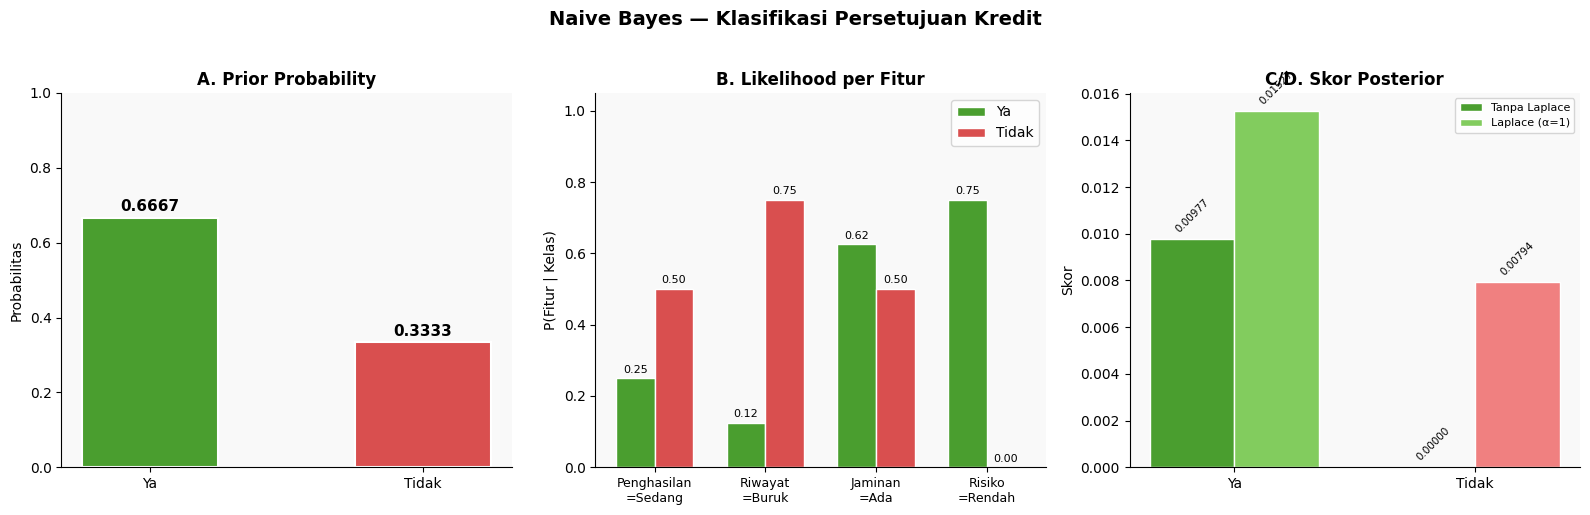


📊 Plot berhasil disimpan sebagai naive_bayes_plot.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Naive Bayes — Klasifikasi Persetujuan Kredit', fontsize=14, fontweight='bold', y=1.02)

colors_kelas = {'Ya': '#4a9e2f', 'Tidak': '#d94f4f'}

# --- Plot 1: Prior Probability ---
ax1 = axes[0]
kelas_list = ['Ya', 'Tidak']
prior_vals = [prior[k] for k in kelas_list]
bars = ax1.bar(kelas_list, prior_vals, color=[colors_kelas[k] for k in kelas_list],
               edgecolor='white', linewidth=1.5, width=0.5)
for bar, val in zip(bars, prior_vals):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.4f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax1.set_title('A. Prior Probability', fontweight='bold', fontsize=12)
ax1.set_ylabel('Probabilitas')
ax1.set_ylim(0, 1.0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.set_facecolor('#f9f9f9')

# --- Plot 2: Likelihood per fitur ---
ax2 = axes[1]
fitur_labels = ['Penghasilan\n=Sedang', 'Riwayat\n=Buruk', 'Jaminan\n=Ada', 'Risiko\n=Rendah']
lk_ya    = [likelihood['Ya'][f]    for f in fitur_kolom]
lk_tidak = [likelihood['Tidak'][f] for f in fitur_kolom]
x = np.arange(len(fitur_labels))
w = 0.35
b1 = ax2.bar(x - w/2, lk_ya,    w, label='Ya',    color=colors_kelas['Ya'],    edgecolor='white')
b2 = ax2.bar(x + w/2, lk_tidak, w, label='Tidak', color=colors_kelas['Tidak'], edgecolor='white')
for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 0.01, f'{h:.2f}',
             ha='center', va='bottom', fontsize=8)
ax2.set_title('B. Likelihood per Fitur', fontweight='bold', fontsize=12)
ax2.set_xticks(x)
ax2.set_xticklabels(fitur_labels, fontsize=9)
ax2.set_ylabel('P(Fitur | Kelas)')
ax2.set_ylim(0, 1.05)
ax2.legend()
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.set_facecolor('#f9f9f9')

# --- Plot 3: Perbandingan Skor (Tanpa vs Dengan Laplace) ---
ax3 = axes[2]
x_pos = np.arange(2)
skor_normal  = [skor.get('Ya', 0), skor.get('Tidak', 0)]
skor_laplac  = [skor_smooth.get('Ya', 0), skor_smooth.get('Tidak', 0)]
w2 = 0.35
ba = ax3.bar(x_pos - w2/2, skor_normal, w2, label='Tanpa Laplace', color=['#4a9e2f','#d94f4f'], edgecolor='white')
bb = ax3.bar(x_pos + w2/2, skor_laplac, w2, label='Laplace (α=1)',  color=['#82cc5e','#f08080'], edgecolor='white')
for bar in list(ba) + list(bb):
    h = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, h + 0.0002, f'{h:.5f}',
             ha='center', va='bottom', fontsize=7.5, rotation=45)
ax3.set_title('C/D. Skor Posterior', fontweight='bold', fontsize=12)
ax3.set_xticks(x_pos)
ax3.set_xticklabels(['Ya', 'Tidak'])
ax3.set_ylabel('Skor')
ax3.legend(fontsize=8)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.set_facecolor('#f9f9f9')

plt.tight_layout()
plt.savefig('naive_bayes_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('\n📊 Plot berhasil disimpan sebagai naive_bayes_plot.png')

---
## ✅ Ringkasan Hasil

| Metode | Skor Ya | Skor Tidak | Prediksi |
|---|---|---|---|
| Naive Bayes (tanpa smoothing) | 0.009766 | 0.000000 | **Ya** |
| Naive Bayes + Laplace (α=1) | 0.015273 | 0.007937 | **Ya** |

> **Kesimpulan:** Pengajuan kredit dengan Penghasilan=Sedang, Riwayat Kredit=Buruk, Jaminan=Ada, Risiko=Rendah diprediksi **DISETUJUI** oleh model Naive Bayes.
>
> ⚠️ **Catatan:** Tanpa Laplace Smoothing, skor kelas "Tidak" = 0 karena tidak ada data training dengan `Risiko=Rendah` pada kelas Tidak (*zero-frequency problem*). Laplace Smoothing mengatasinya dan tetap menghasilkan prediksi yang sama.